# 미슐랭 1스타, 2스타, 3스타 데이터 분석 및 처리

## 프로젝트 개요
각 데이터셋(1스타, 2스타, 3스타)을 개별적으로 분석, 처리, 시각화합니다.
이를 통해 각 데이터의 특징을 파악하고, 필요 시 병합하여 모델링에 활용할 수 있습니다.

---

## 1. 데이터 로드 및 확인
각 데이터셋(1스타, 2스타, 3스타)을 로드하고 기본 정보를 확인합니다.
 병합합니다.
인 정보를 확인합니다.


In [1]:
# 필요한 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 로드
file_path1 = './kaggle/input/michelin-restaurants/one-star-michelin-restaurants-2024.csv'
file_path2 = './kaggle/input/michelin-restaurants/two-stars-michelin-restaurants-2024.csv'
file_path3 = './kaggle/input/michelin-restaurants/three-stars-michelin-restaurants-2024.csv'

# 데이터 읽기
data1 = pd.read_csv(file_path1)  # 1스타
data2 = pd.read_csv(file_path2)  # 2스타
data3 = pd.read_csv(file_path3)  # 3스타

# 데이터 확인
print("1스타 데이터:")
print(data1.head(), "\n")
print("2스타 데이터:")
print(data2.head(), "\n")
print("3스타 데이터:")
print(data3.head(), "\n")


1스타 데이터:
   Year   Latitude   Longitude        City    Region                Cuisine  \
0  2024  13.727437  100.587236     Bangkok  Thailand      Thai contemporary   
1  2024  13.898489  100.515133  Nonthaburi  Thailand     Thai, Contemporary   
2  2024  13.721191  100.571348     Bangkok  Thailand         Modern Cuisine   
3  2024  13.737689  100.543446     Bangkok  Thailand         Modern Cuisine   
4  2024  13.740117  100.540173     Bangkok  Thailand  European Contemporary   

   Price  Stars  
0      3      1  
1      3      1  
2      3      1  
3      4      1  
4      4      1   

2스타 데이터:
   Year   Latitude   Longitude     City    Region               Cuisine  \
0  2024  13.727250  100.578280  Bangkok  Thailand  Indian, Contemporary   
1  2024  13.751550  100.605510  Bangkok  Thailand     Thai contemporary   
2  2024  13.710808  100.545726  Bangkok  Thailand  German, Contemporary   
3  2024  13.721501  100.517170  Bangkok  Thailand   French Contemporary   
4  2024  13.713092  10

## 2. 데이터 전처리: 도시국가의 `Region` 결측치 처리

### 배경
데이터셋에서 `Region` 열이 비어 있는 경우가 발견되었습니다.  
이는 특정 도시국가(예: 아부다비, 홍콩, 마카오 등)에서는 `Region` 정보가 제공되지 않고, 도시(`City`) 수준에서만 데이터가 구분되기 때문입니다.  
따라서, 이러한 도시국가의 경우, 동일한 행의 `City` 값을 `Region` 결측치에 복사하여 대체했습니다.

---

### 처리 과정
1. 데이터의 `Region` 열에서 결측치를 확인합니다.
2. 결측치가 있는 행의 경우, 해당 행의 `City` 값을 `Region` 값으로 대체합니다.
3. 대체 전후의 데이터 행 수를 비교하여 데이터 무결성을 확인합니다.
4. 결과를 확인 후, one-star,two-stars,three-stars 데이터들을 하나의 데이터로 병합하고, 확인합니다.

---

### 처리 코드.


In [ ]:
# 대체 전 데이터 행 길이 저장
length_before_1 = len(data1)
length_before_2 = len(data2)
length_before_3 = len(data3)

print(f"1스타 데이터 대체 전 행 길이: {length_before_1}")
print(f"2스타 데이터 대체 전 행 길이: {length_before_2}")
print(f"3스타 데이터 대체 전 행 길이: {length_before_3}")

# Region의 결측치를 City 값으로 대체
data1['Region'] = data1['Region'].fillna(data1['City'])
data2['Region'] = data2['Region'].fillna(data2['City'])
data3['Region'] = data3['Region'].fillna(data3['City'])

# 대체 후 데이터 행 길이 저장
length_after_1 = len(data1)
length_after_2 = len(data2)
length_after_3 = len(data3)

print(f"1스타 데이터 대체 후 행 길이: {length_after_1}")
print(f"2스타 데이터 대체 후 행 길이: {length_after_2}")
print(f"3스타 데이터 대체 후 행 길이: {length_after_3}")

# 변화 확인
print(f"1스타 데이터 행 변화: {length_after_1 - length_before_1}")
print(f"2스타 데이터 행 변화: {length_after_2 - length_before_2}")
print(f"3스타 데이터 행 변화: {length_after_3 - length_before_3}")

# 1, 2, 3스타 데이터를 합쳐 하나의 데이터프레임으로 생성
data = pd.concat([data1, data2, data3], axis=0)

# 병합된 데이터 확인
print(f"병합된 데이터 총 행 개수: {len(data)}")
print("병합된 데이터 상위 5개 행:\n", data.head())

# 병합된 데이터의 기본 정보 확인
print("병합된 데이터 정보:")
print(data.info())

# 병합된 데이터에서 'Price'와 'Stars' 열에 대한 통계 요약
print("Price와 Stars 열의 통계 요약:")
print(data[['Price', 'Stars']].describe())



1스타 데이터 대체 전 행 길이: 2953
2스타 데이터 대체 전 행 길이: 489
3스타 데이터 대체 전 행 길이: 147
1스타 데이터 대체 후 행 길이: 2953
2스타 데이터 대체 후 행 길이: 489
3스타 데이터 대체 후 행 길이: 147
1스타 데이터 행 변화: 0
2스타 데이터 행 변화: 0
3스타 데이터 행 변화: 0
병합된 데이터 총 행 개수: 3589
병합된 데이터 상위 5개 행:
    Year   Latitude   Longitude        City    Region                Cuisine  \
0  2024  13.727437  100.587236     Bangkok  Thailand      Thai contemporary   
1  2024  13.898489  100.515133  Nonthaburi  Thailand     Thai, Contemporary   
2  2024  13.721191  100.571348     Bangkok  Thailand         Modern Cuisine   
3  2024  13.737689  100.543446     Bangkok  Thailand         Modern Cuisine   
4  2024  13.740117  100.540173     Bangkok  Thailand  European Contemporary   

   Price  Stars  
0      3      1  
1      3      1  
2      3      1  
3      4      1  
4      4      1  
병합된 데이터 정보:
<class 'pandas.core.frame.DataFrame'>
Index: 3589 entries, 0 to 146
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  ----- 

## 3. 데이터 탐색 (EDA)

### 변수 분포 확인
각 주요 변수의 분포를 시각화하여 데이터의 특성을 파악합니다.  
특히 `Price`(가격), `Stars`(스타 등급), `Region`(지역), `Cuisine`(요리 유형) 등을 중심으로 분석합니다.


---

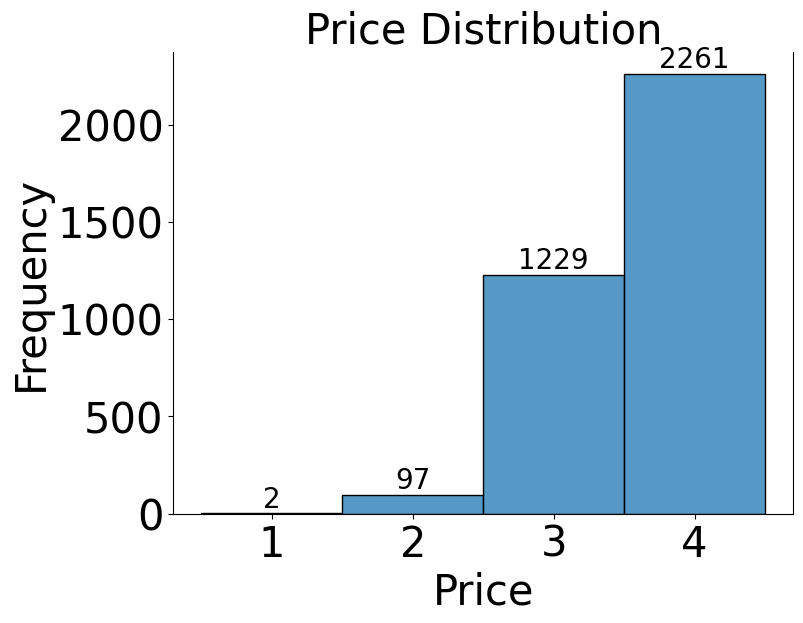

In [3]:
# 가격(Price) 분포 시각화 (1, 2, 3, 4, 5 정수 단위로만 표시)
plt.figure(figsize=(8, 6))
ax = sns.histplot(data['Price'], bins=[1, 2, 3, 4, 5, 6], discrete=True)

# 데이터 값(빈도) 표시
for container in ax.containers:
    # 각 막대에 대해 빈도 표시
    ax.bar_label(container, fmt='%d', label_type='edge', fontsize=20)
ax.spines['top'].set_visible(False)
plt.title('Price Distribution', fontsize=30)
plt.xlabel('Price', fontsize=30)
plt.ylabel('Frequency', fontsize=30)
plt.xticks([1, 2, 3, 4], fontsize=30)  # X축 값 고정
plt.yticks(fontsize=30)
plt.show()


### 스타 등급(Stars) 분포 시각화

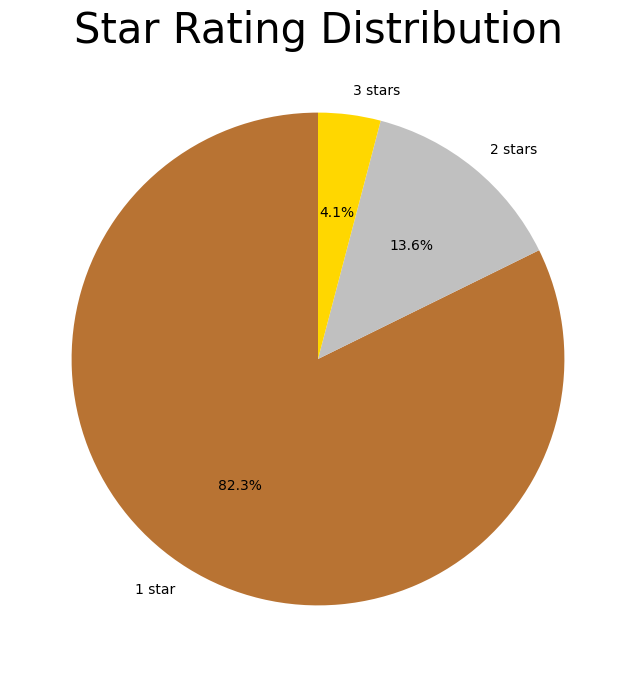

In [4]:
import matplotlib.pyplot as plt

# 스타 등급 분포 계산
star_counts = data['Stars'].value_counts()

# 라벨 생성 (예: "1 star", "2 stars", ...)
labels = [f"{int(star)} star" if star == 1 else f"{int(star)} stars" for star in star_counts.index]

# 금, 은, 동 색상 설정
colors = ['#B87333','#C0C0C0','#FFD700' ]  # gold, silver, copper

# 원형 그래프 생성
plt.figure(figsize=(8, 8))
plt.pie(
    star_counts, 
    labels=labels,  # 라벨 설정
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors  # 사용자 지정 색상
)
plt.title('Star Rating Distribution', fontsize=30)
plt.show()


### 지역(Region) 분포 시각화

In [ ]:
import folium

# 지도 중심 설정
map_center = [data['Latitude'].mean(), data['Longitude'].mean()]

# 지도 생성
world_map = folium.Map(location=map_center, zoom_start=2)

# 마커 추가
for _, row in data.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=row['Stars'] * 2,  # Stars에 비례하는 마커 크기
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.7,
        popup=f"City: {row['City']}<br>Stars: {row['Stars']}"
    ).add_to(world_map)

# 지도 저장 및 출력
world_map.save("world_map.html")
world_map


### 요리 유형(Cuisine) 분포 시각화

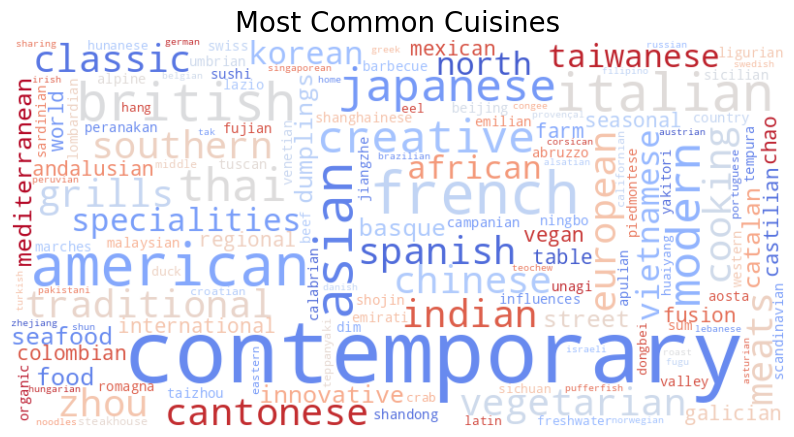

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# 요리 유형 데이터를 하나의 문자열로 결합
# 쉼표로 단어 분리
cuisines = data['Cuisine'].dropna().str.split(',').explode()

# 공백 제거 및 소문자로 변환
cuisines = cuisines.str.strip().str.lower()
cuisines = cuisines.drop_duplicates()  # 중복 제거

# 단어들을 하나의 문자열로 결합
cuisines_text = ' '.join(cuisines)

# 'cuisine'을 제거하기 위해 STOPWORDS에 추가
custom_stopwords = STOPWORDS.union({'cuisine'})

# WordCloud 생성
wc = WordCloud(width=800, height=400, stopwords=custom_stopwords, colormap='coolwarm', background_color='white').generate(cuisines_text)

# WordCloud 시각화
plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.title('Most Common Cuisines', fontsize=20)
plt.axis('off')
plt.show()


## 4. 머신러닝 모델링 준비

### 입력 데이터와 타겟 변수 분리

- **가격 예측 (`Price`)**
  - **입력 변수 (`X_price`)**:
    - `City`, `Region`, `Cuisine`, `Stars`
  - **타겟 변수 (`y_price`)**:
    - `Price`

- **별 등급 예측 (`Stars`)**
  - **입력 변수 (`X_stars`)**:
    - `City`, `Region`, `Cuisine`, `Price`
  - **타겟 변수 (`y_stars`)**:
    - `Stars`

---

### 데이터 분할

- 학습 데이터와 테스트 데이터를 나누어 모델 학습 및 평가를 수행합니다.
- 데이터를 분할할 때는 80:20의 비율로 나누는 것을 기본으로 설정합니다.
- **가격 예측 데이터**와 **별 등급 예측 데이터**에 각각 적용합니다.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import pandas as pd
# 'Stars' 열 변환 (1부터 시작 -> 0부터 시작)
data['Stars'] = data['Stars'].astype(int) - 1

# 'Price' 열 변환 (1부터 시작 -> 0부터 시작)
data['Price'] = data['Price'] - 1


# 복사본 생성
X_price = data[['City', 'Region', 'Cuisine', 'Stars']].copy()
y_price = data['Price'].copy()
X_stars = data[['City', 'Region', 'Cuisine', 'Price']].copy()
y_stars = data['Stars'].copy()

# Count Encoding
for col in ['City', 'Region', 'Cuisine']:
    count_dict = data[col].value_counts().to_dict()
    X_price[col] = X_price[col].map(count_dict)
    X_stars[col] = X_stars[col].map(count_dict)

# 스케일링
scaler = StandardScaler()
numeric_cols_price = X_price.select_dtypes(include=['int64', 'float64']).columns
numeric_cols_stars = X_stars.select_dtypes(include=['int64', 'float64']).columns
X_price[numeric_cols_price] = scaler.fit_transform(X_price[numeric_cols_price])
X_stars[numeric_cols_stars] = scaler.fit_transform(X_stars[numeric_cols_stars])

# 데이터 분할 (Stratified Sampling)
X_price_train, X_price_test, y_price_train, y_price_test = train_test_split(
    X_price, y_price, test_size=0.2, random_state=42, stratify=y_price)

X_stars_train, X_stars_test, y_stars_train, y_stars_test = train_test_split(
    X_stars, y_stars, test_size=0.2, random_state=42, stratify=y_stars)

# 결과 확인
print(f"X_price_train shape: {X_price_train.shape}, y_price_train shape: {y_price_train.shape}")
print(f"X_price_test shape: {X_price_test.shape}, y_price_test shape: {y_price_test.shape}")
print(f"X_stars_train shape: {X_stars_train.shape}, y_stars_train shape: {y_stars_train.shape}")
print(f"X_stars_test shape: {X_stars_test.shape}, y_stars_test shape: {y_stars_test.shape}")


print("y_price_train 클래스 값:", y_price_train.unique())
print("y_price_test 클래스 값:", y_price_test.unique())


X_price_train shape: (2871, 4), y_price_train shape: (2871,)
X_price_test shape: (718, 4), y_price_test shape: (718,)
X_stars_train shape: (2871, 4), y_stars_train shape: (2871,)
X_stars_test shape: (718, 4), y_stars_test shape: (718,)
y_price_train 클래스 값: [3 2 1 0]
y_price_test 클래스 값: [3 2 1]


## 5. 머신러닝 모델 학습



### 스타 등급 예측 모델
- **알고리즘**:
  - `Logistic Regression`
  - `Random Forest Classifier`
  - `XGBoost Classifier`

- **평가 지표**:
  - **정확도 (Accuracy)**: 전체 예측 중 올바르게 분류된 비율.
  - **정밀도 (Precision)**: 특정 스타 등급을 예측했을 때, 실제로 해당 등급인 경우의 비율.
  - **재현율 (Recall)**: 실제 특정 스타 등급 데이터를 모델이 얼마나 잘 찾아냈는지 평가.
  - **F1 점수**: 정밀도와 재현율의 조화 평균 값.

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

           0       0.82      1.00      0.90       591
           1       1.00      0.00      0.00        98
           2       1.00      0.00      0.00        29

    accuracy                           0.82       718
   macro avg       0.94      0.33      0.30       718
weighted avg       0.85      0.82      0.74       718

Classification Report for Random Forest Classifier:

              precision    recall  f1-score   support

           0       0.87      0.78      0.82       591
           1       0.19      0.21      0.20        98
           2       0.15      0.41      0.22        29

    accuracy                           0.69       718
   macro avg       0.40      0.47      0.42       718
weighted avg       0.75      0.69      0.71       718

Classification Report for XGBoostClassifier:

              precision    recall  f1-score   support

           0       0.84      0.94   

/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [22:15:39] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "scale_pos_weight", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


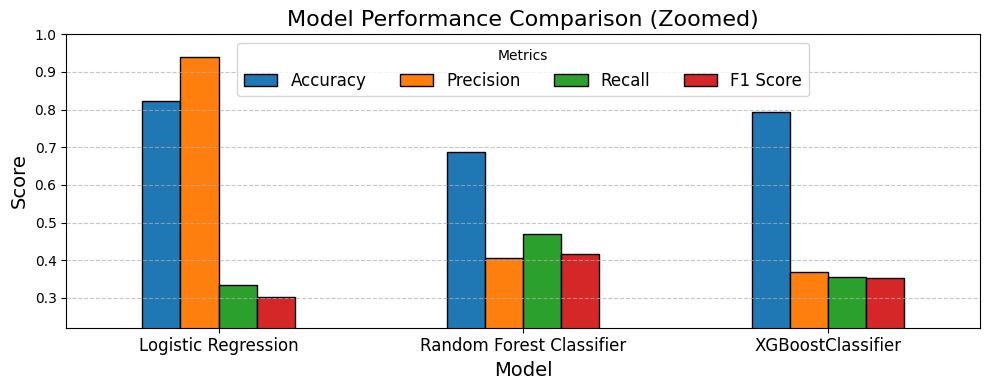

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

# 결과 저장용 딕셔너리
results = {}

# 모델 정의
star_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'XGBoostClassifier': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss', scale_pos_weight=1)
}

# 각 모델 학습 및 평가
for model_name, model in star_models.items():
    # 모델 학습
    model.fit(X_stars_train, y_stars_train)
    
    # 예측
    y_pred = model.predict(X_stars_test)
    
    # 평가 지표 계산
    accuracy = accuracy_score(y_stars_test, y_pred)
    precision = precision_score(y_stars_test, y_pred, average='macro', zero_division=1)
    recall = recall_score(y_stars_test, y_pred, average='macro', zero_division=1)
    f1 = f1_score(y_stars_test, y_pred, average='macro', zero_division=1)
    
    # 결과 저장
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

    # Classification report 출력
    print(f"Classification Report for {model_name}:\n")
    print(classification_report(y_stars_test, y_pred, zero_division=1))

# 결과 출력
results_df = pd.DataFrame(results).T
print("모델 평가 결과:")
print(results_df)

# 평균값 계산 함수
def average(results):
    results_df = pd.DataFrame(results).T
    return results_df.mean().mean()

# 평균값 계산
average_score = average(results)

# 함수 수정: 평균값을 기준으로 특정 범위에서 확대하여 그래프 표시
def plot_model_comparison_zoom(results, zoom_range=None):
    if zoom_range is None:
        zoom_range = (average_score - 0.3, 1.0)  # 기본 확대 범위 설정
    
    # DataFrame으로 변환
    results_df = pd.DataFrame(results).T

    # 그래프 생성
    fig, ax = plt.subplots(figsize=(10, 4))
    results_df.plot(kind='bar', ax=ax, edgecolor='black')

    # 제목 및 축 설정
    plt.title('Model Performance Comparison (Zoomed)', fontsize=16)
    plt.ylabel('Score', fontsize=14)
    plt.xlabel('Model', fontsize=14)
    plt.xticks(rotation=0, fontsize=12)
    plt.ylim(zoom_range)  # 설정된 범위에서 확대
    plt.legend(title='Metrics',fontsize=12,loc='upper center',bbox_to_anchor=(0.5, 1),  ncol=len(results_df.columns) )
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# 실행
plot_model_comparison_zoom(results)
#최적모델 선택
best_model_star = star_models['Random Forest Classifier']  # Random Forest Classifier를 가장 좋은 모델로 선택

### 가격 예측 모델
- **알고리즘**:
  - `Logistic Regression`
  - `Random Forest Classifier`
  - `XGBoost Classifier`

- **평가 지표**:
  - **정확도 (Accuracy)**: 전체 예측 중 올바르게 분류된 비율.
  - **정밀도 (Precision)**: 특정 가격대를 예측했을 때, 실제로 해당 가격대인 경우의 비율.
  - **재현율 (Recall)**: 실제 특정 가격대인 데이터를 모델이 얼마나 잘 찾아냈는지 평가.
  - **F1 점수**: 정밀도와 재현율의 조화 평균 값.

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

           1       1.00      0.00      0.00        20
           2       0.57      0.11      0.19       246
           3       0.65      0.96      0.78       452

    accuracy                           0.64       718
   macro avg       0.74      0.36      0.32       718
weighted avg       0.63      0.64      0.55       718

Classification Report for Random Forest Classifier:

              precision    recall  f1-score   support

           1       0.13      0.25      0.17        20
           2       0.52      0.64      0.57       246
           3       0.80      0.67      0.73       452

    accuracy                           0.65       718
   macro avg       0.48      0.52      0.49       718
weighted avg       0.69      0.65      0.66       718

Classification Report for XGBoostClassifier:

              precision    recall  f1-score   support

           1       0.22      0.10   

/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [22:15:40] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "scale_pos_weight", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


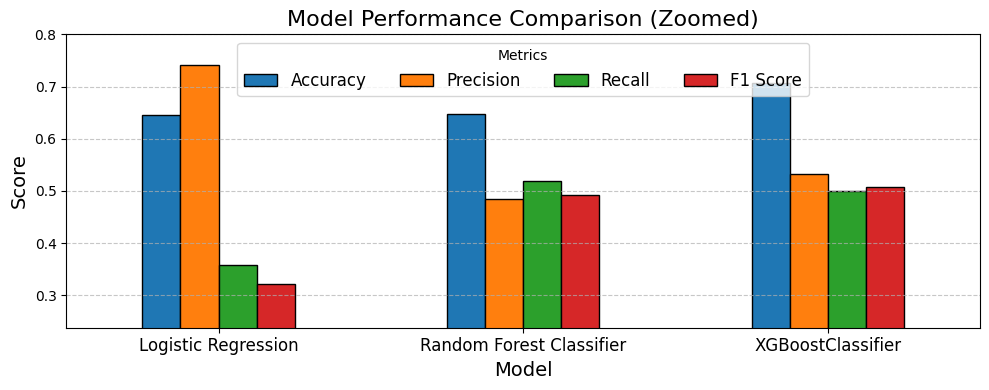

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

# 결과 저장용 딕셔너리
results = {}

# 모델 정의
price_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'XGBoostClassifier': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss', scale_pos_weight=1)
}

# 각 모델 학습 및 평가
for model_name, model in price_models.items():
    # 모델 학습
    model.fit(X_price_train, y_price_train)
    
    # 예측
    y_pred = model.predict(X_price_test)
    
    # 평가 지표 계산
    accuracy = accuracy_score(y_price_test, y_pred)
    precision = precision_score(y_price_test, y_pred, average='macro', zero_division=1)
    recall = recall_score(y_price_test, y_pred, average='macro', zero_division=1)
    f1 = f1_score(y_price_test, y_pred, average='macro', zero_division=1)
    
    # 결과 저장
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

    # Classification report 출력
    print(f"Classification Report for {model_name}:\n")
    print(classification_report(y_price_test, y_pred, zero_division=1))

# 결과 출력
results_df = pd.DataFrame(results).T
print("모델 평가 결과:")
print(results_df)


# 평균값 계산 함수
def average(results):
    results_df = pd.DataFrame(results).T
    return results_df.mean().mean()

# 평균값 계산
average_score = average(results)

# 함수 수정: 평균값을 기준으로 특정 범위에서 확대하여 그래프 표시
def plot_model_comparison_zoom(results, zoom_range=None):
    if zoom_range is None:
        zoom_range = (average_score - 0.3, 0.8)  # 기본 확대 범위 설정
    
    # DataFrame으로 변환
    results_df = pd.DataFrame(results).T

    # 그래프 생성
    fig, ax = plt.subplots(figsize=(10, 4))
    results_df.plot(kind='bar', ax=ax, edgecolor='black')

    # 제목 및 축 설정
    plt.title('Model Performance Comparison (Zoomed)', fontsize=16)
    plt.ylabel('Score', fontsize=14)
    plt.xlabel('Model', fontsize=14)
    plt.xticks(rotation=0, fontsize=12)
    plt.ylim(zoom_range)  # 설정된 범위에서 확대
    plt.legend(title='Metrics',fontsize=12,loc='upper center',bbox_to_anchor=(0.5, 1),  ncol=len(results_df.columns) )
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# 실행
plot_model_comparison_zoom(results)
#최적 모델 선택
best_model_price = price_models['XGBoostClassifier']  # XGBoostClassifier를 가장 좋은 모델로 선택

### 안성재 쉐프의 모수의 위치는 서울,대한민국,메뉴는 innovative, 스타는 3스타였었다. 가격은 32만원으로 price등급으로는 4단계였는데 그 결과를 한번 확인해본다.

In [8]:

# 새로운 데이터 포인트 생성: 안성재 쉐프의 모수 정보
new_data_mosu = {
    'City': ['Seoul'],
    'Region': ['South Korea'],
    'Cuisine': ['Innovative'],
    'Stars': [2]  # 3STAR -> 모델 입력에 맞게 2로 조정 (0-indexed)
}
new_data_mosu_df = pd.DataFrame(new_data_mosu)

# Count Encoding: 기존 데이터의 분포를 기반으로 새로운 데이터에 적용
for col in ['City', 'Region', 'Cuisine']:
    count_dict = data[col].value_counts().to_dict()
    new_data_mosu_df[col] = new_data_mosu_df[col].map(count_dict).fillna(0)  # NaN 값 0으로 대체

# 'Stars'를 'Price'로 이름 변경 (학습 데이터와 동일하게 맞춤)
new_data_mosu_df = new_data_mosu_df.rename(columns={'Stars': 'Price'})

# 학습 데이터와 동일한 열 순서로 정렬
feature_names = ['City', 'Region', 'Cuisine', 'Price']
new_data_mosu_df = new_data_mosu_df[feature_names]

# 스케일링: 기존 모델 학습에서 사용한 스케일러 적용
new_data_scaled_mosu = scaler.transform(new_data_mosu_df)

# XGBoostClassifier로 예측
predicted_price_mosu = best_model_price.predict(new_data_scaled_mosu)

# 예측된 가격 범주를 원래 값으로 복원
actual_price_category_mosu = predicted_price_mosu[0] + 1  # 0부터 시작한 값을 1부터 시작하는 값으로 복원

print(f"Predicted Price Category for Mosu : {actual_price_category_mosu}")


Predicted Price Category for Mosu : 4


## Price는 4인 경우가 가장 많고, Star은 1인경우가 가장 많다. 따라서 Price를 4로 예측하고, Star를 1로 예측하면 각각에 대해서 무조건 정확도가 최소 60퍼센트는 넘긴다. 따라서 각 Star개수에 따라서 데이터를 분리하여, 모델에 적용시켜서 정확도가 얼마나 되는지 판단한다.

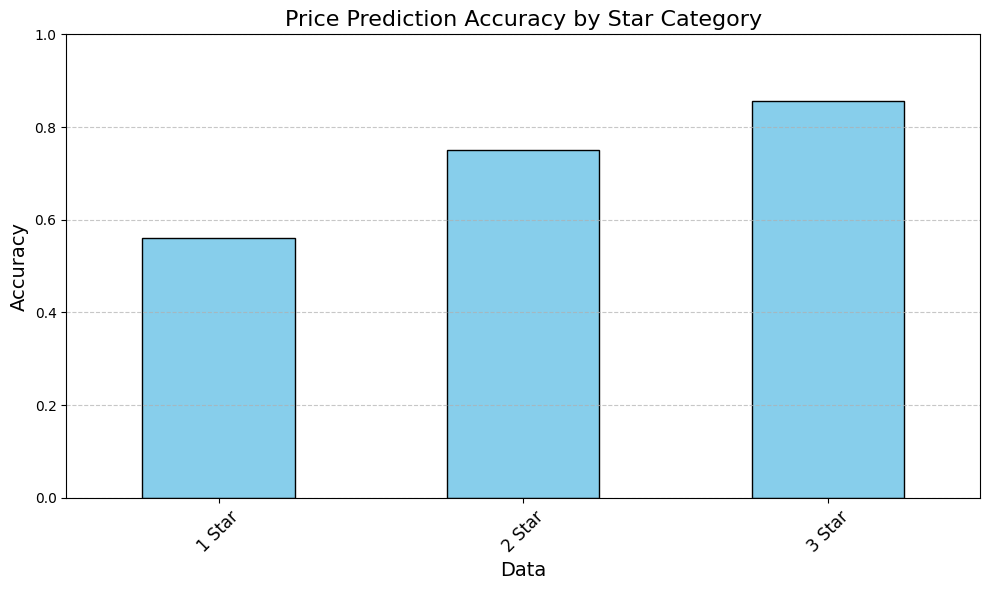

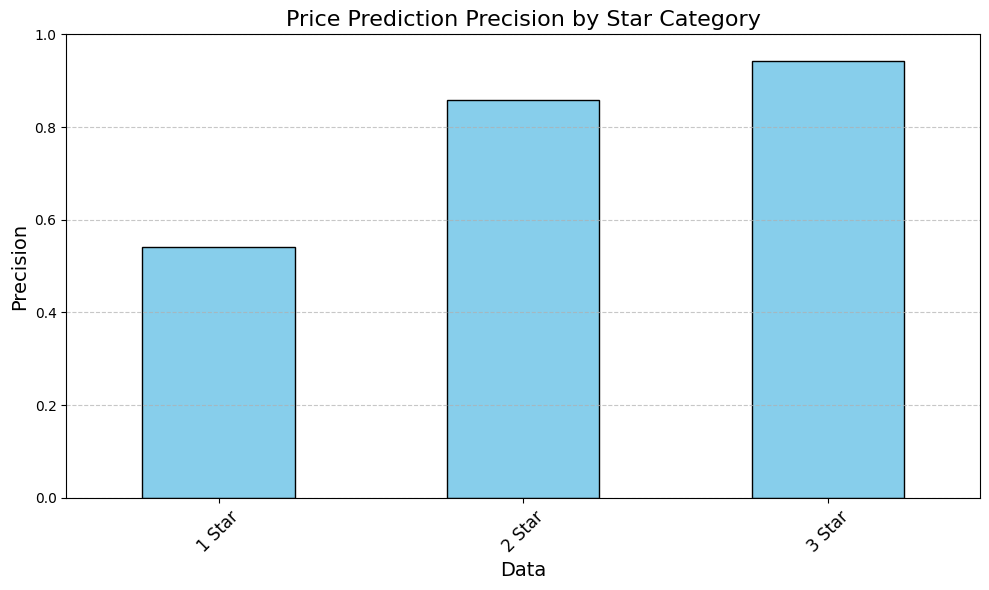

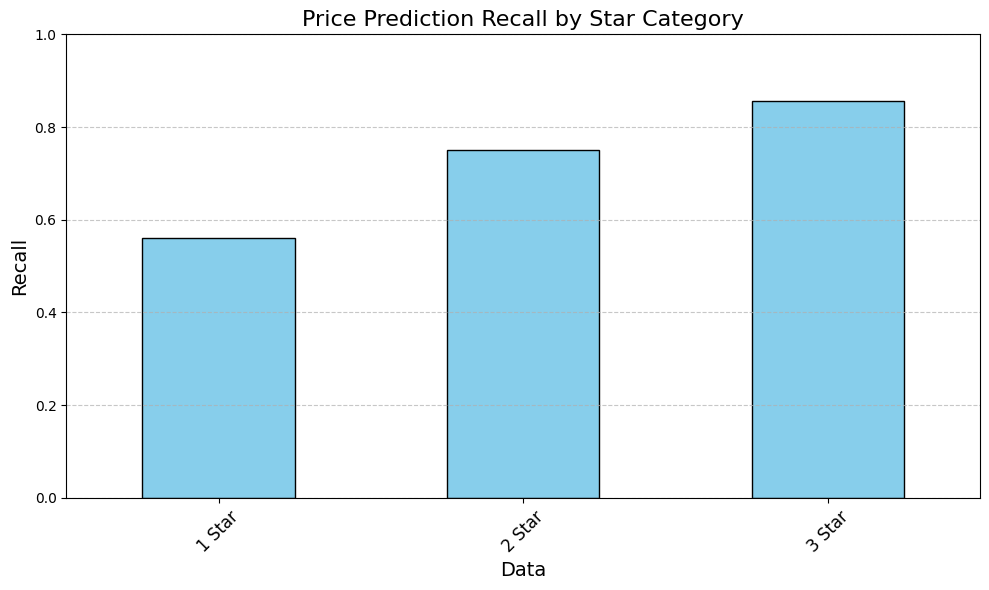

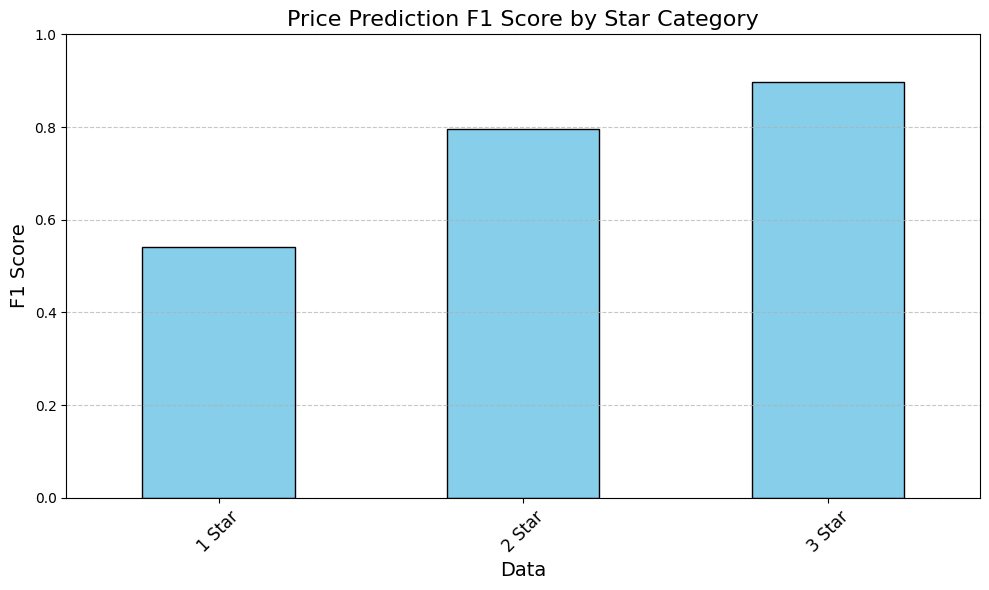


==================== Price Prediction Performance Metrics ====================
        Accuracy  Precision    Recall  F1 Score
1 Star  0.560786   0.540650  0.560786  0.542084
2 Star  0.750511   0.857788  0.750511  0.796288
3 Star  0.857143   0.942857  0.857143  0.897959




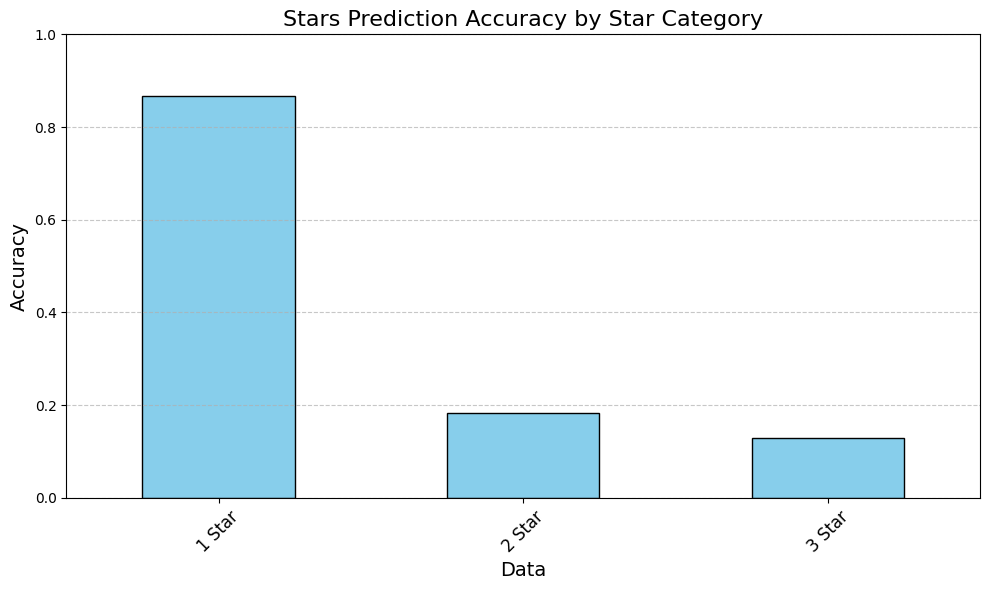

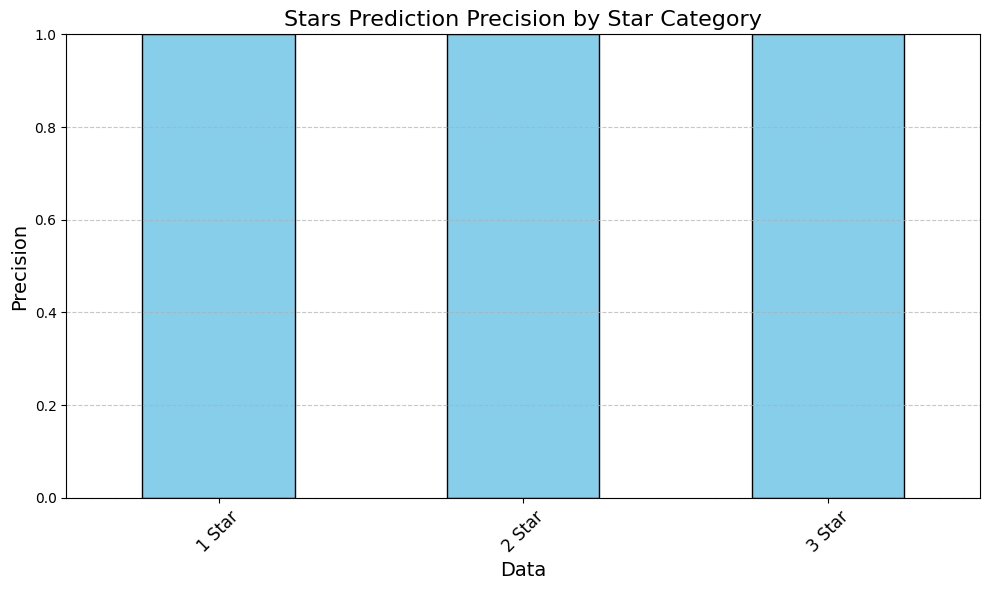

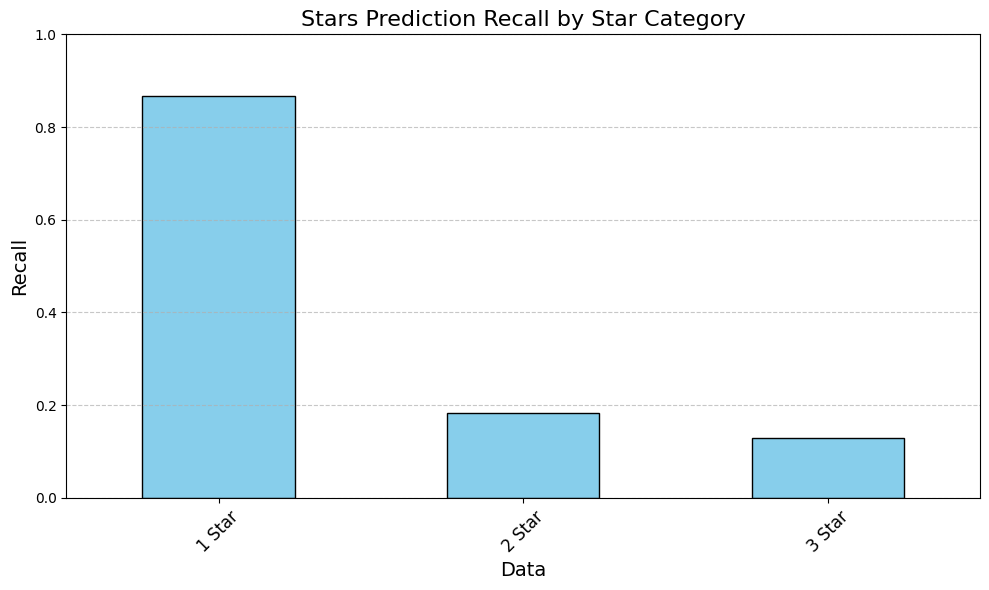

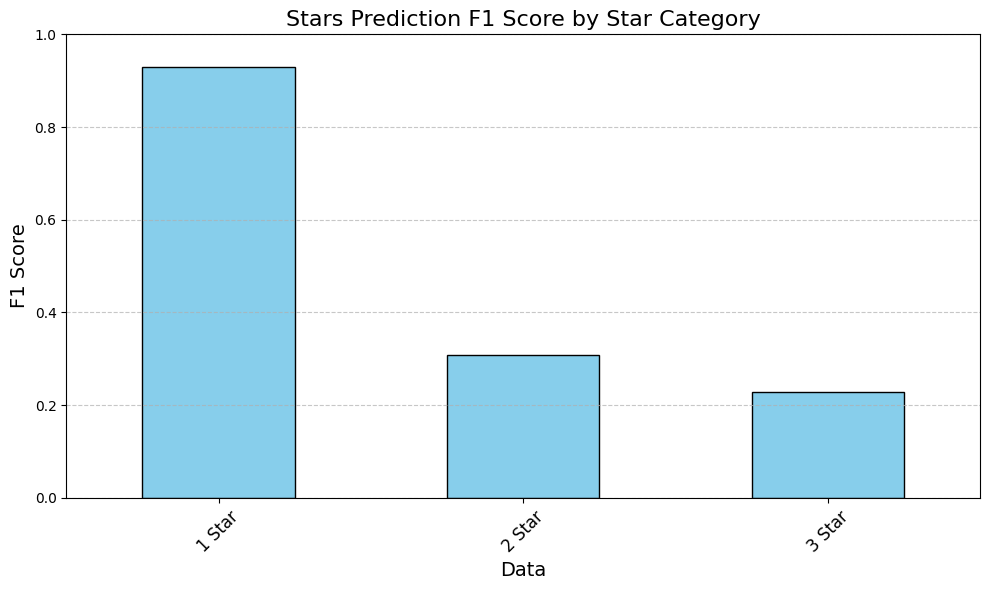


==================== Stars Prediction Performance Metrics ====================
        Accuracy  Precision    Recall  F1 Score
1 Star  0.866915        1.0  0.866915  0.928714
2 Star  0.182004        1.0  0.182004  0.307958
3 Star  0.129252        1.0  0.129252  0.228916




In [9]:
# 필요한 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 데이터 로드
file_path1 = './kaggle/input/michelin-restaurants/one-star-michelin-restaurants-2024.csv'
file_path2 = './kaggle/input/michelin-restaurants/two-stars-michelin-restaurants-2024.csv'
file_path3 = './kaggle/input/michelin-restaurants/three-stars-michelin-restaurants-2024.csv'

data1 = pd.read_csv(file_path1)  # 1스타
data2 = pd.read_csv(file_path2)  # 2스타
data3 = pd.read_csv(file_path3)  # 3스타
# 데이터 로드 후 변환
for data in [data1, data2, data3]:
    # 결측치 처리
    data['Region'] = data['Region'].fillna(data['City'])
    
    # 'Stars' 열 변환 (1부터 시작 -> 0부터 시작)
    data['Stars'] = data['Stars'].astype(int) - 1

    # 'Price' 열 변환 (1부터 시작 -> 0부터 시작)
    data['Price'] = data['Price'] - 1

# 결측치 처리
for data in [data1, data2, data3]:
    data['Region'] = data['Region'].fillna(data['City'])

# 학습된 모델에서 사용한 열 목록
price_features = ['City', 'Region', 'Cuisine', 'Stars']  # 'Price' 예측 시 사용된 열
star_features = ['City', 'Region', 'Cuisine', 'Price']  # 'Stars' 예측 시 사용된 열

# 전처리 함수: 필요한 열만 유지
def preprocess_data(data, target_col, features):
    X = data[features].copy()  # 복사본 생성
    y = data[target_col]  # 타겟 설정

    # Count Encoding (범주형 데이터 -> 숫자형 데이터)
    for col in ['City', 'Region', 'Cuisine']:
        count_dict = data[col].value_counts().to_dict()
        X[col] = X[col].map(count_dict).astype(float)  # 숫자형으로 변환

    # 스케일링
    scaler = StandardScaler()
    numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
    X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

    return X, y

# 평가 함수 수정: 전체 데이터를 모델에 입력
def evaluate_model_on_entire_data(model, X, y):
    # 모델에 전체 데이터를 입력하여 예측
    y_pred = model.predict(X)

    # 평가
    results = {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, average='weighted', zero_division=1),
        'Recall': recall_score(y, y_pred, average='weighted', zero_division=1),
        'F1 Score': f1_score(y, y_pred, average='weighted', zero_division=1)
    }

    return results

# 결과 저장 딕셔너리 초기화
results_price = {}
results_stars = {}

for name, data in zip(['1 Star', '2 Star', '3 Star'], [data1, data2, data3]):
    # Price 예측: 'Stars' 포함, 나머지 제거
    X_price, y_price = preprocess_data(data, 'Price', price_features)
    results_price[name] = evaluate_model_on_entire_data(best_model_price, X_price, y_price)

    # Stars 예측: 'Price' 포함, 나머지 제거
    X_stars, y_stars = preprocess_data(data, 'Stars', star_features)
    results_stars[name] = evaluate_model_on_entire_data(best_model_star, X_stars, y_stars)

# 결과 시각화 함수: 모든 성능 지표를 시각화
def plot_all_metrics(results, title_prefix):
    # 결과를 DataFrame으로 변환
    results_df = pd.DataFrame(results).T

    # 각 성능 지표에 대해 그래프 생성
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
    for metric in metrics:
        results_df[metric].plot(kind='bar', figsize=(10, 6), color='skyblue', edgecolor='black')
        plt.title(f"{title_prefix} {metric} by Star Category", fontsize=16)
        plt.xlabel('Data', fontsize=14)
        plt.ylabel(metric, fontsize=14)
        plt.xticks(rotation=45, fontsize=12)
        plt.ylim(0, 1)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    # 텍스트로 결과 출력
    print(f"\n{'='*20} {title_prefix} Performance Metrics {'='*20}")
    print(results_df)
    print("\n")

# Price와 Stars에 대해 결과 시각화
plot_all_metrics(results_price, 'Price Prediction')
plot_all_metrics(results_stars, 'Stars Prediction')




In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, Concatenate, Average, Lambda
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import backend as K
import tensorflow as tf

# 데이터 로드
file_path1 = './kaggle/input/michelin-restaurants/one-star-michelin-restaurants-2024.csv'
file_path2 = './kaggle/input/michelin-restaurants/two-stars-michelin-restaurants-2024.csv'
file_path3 = './kaggle/input/michelin-restaurants/three-stars-michelin-restaurants-2024.csv'

data1 = pd.read_csv(file_path1)  # 1스타
data2 = pd.read_csv(file_path2)  # 2스타
data3 = pd.read_csv(file_path3)  # 3스타

# 데이터 전처리
for data in [data1, data2, data3]:
    data['Region'] = data['Region'].fillna(data['City'])
    data['Stars'] = data['Stars'].astype(int) - 1
    data['Price'] = data['Price'] - 1

all_data = pd.concat([data1, data2, data3], axis=0).reset_index(drop=True)

# city, region factorization (with UNK)
def factorize_with_unk(series):
    uniq = series.dropna().unique().tolist()
    uniq = ['UNK'] + uniq
    mapper = {v:i for i,v in enumerate(uniq)}
    return series.apply(lambda x: mapper.get(x,0)), mapper

all_data['City_idx'], city_map = factorize_with_unk(all_data['City'])
all_data['Region_idx'], region_map = factorize_with_unk(all_data['Region'])

# Cuisine 처리: 쉼표로 구분된 모든 카테고리 사용
# 모든 cuisine 토큰 추출
def split_cuisines(c):
    if pd.isnull(c):
        return ['UNK']
    return [x.strip() for x in c.split(',') if x.strip() != '']

all_data['Cuisines_list'] = all_data['Cuisine'].apply(split_cuisines)
all_cuisines = set()
for c_list in all_data['Cuisines_list']:
    all_cuisines.update(c_list)
all_cuisines = ['UNK'] + list(all_cuisines)
cuisine_map = {v:i for i,v in enumerate(all_cuisines)}

def cuisines_to_idx_list(c_list):
    return [cuisine_map.get(x, 0) for x in c_list]

all_data['Cuisine_idx_list'] = all_data['Cuisines_list'].apply(cuisines_to_idx_list)

# 이제 임베딩 모델 4개를 만든다.
# Hyperparameters
embedding_dim = 8
epochs = 20
batch_size = 32

# (a) (latitude, longitude, city, region) -> price 모델
def build_city_region_price_model(city_size, region_size):
    input_city = Input(shape=(1,))
    input_region = Input(shape=(1,))
    input_lat = Input(shape=(1,))
    input_lon = Input(shape=(1,))
    
    city_emb = Embedding(city_size, embedding_dim)(input_city)
    region_emb = Embedding(region_size, embedding_dim)(input_region)
    city_emb_f = Flatten()(city_emb)
    region_emb_f = Flatten()(region_emb)
    
    merged = Concatenate()([city_emb_f, region_emb_f, input_lat, input_lon])
    hidden = Dense(16, activation='relu')(merged)
    output = Dense(1, activation='linear')(hidden)  # price 예측 (회귀처럼 다룰지, 분류면 softmax 필요. 여기서는 0~3 클래스라고 했으니 분류)
    
    # Price는 0~3 클래스이므로 softmax 분류로 변경
    # Price가 4개 클래스라고 가정하면:
    out = Dense(4, activation='softmax')(hidden)

    model = Model(inputs=[input_city, input_region, input_lat, input_lon], outputs=out)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# (b) cuisine -> price 모델
# cuisine은 여러 개의 인덱스를 입력받아 평균 임베딩을 구한 뒤 price 예측
def build_cuisine_price_model(cuisine_size, max_cuisine_count=10):
    # max_cuisine_count: 한 레스토랑당 최대 몇 개의 cuisine 카테고리를 사용할지 결정
    # 실제 데이터에 맞추어 충분히 큰 값으로 설정하거나, padding/ truncation 수행
    input_cuisine = Input(shape=(max_cuisine_count,))
    cuisine_emb_layer = Embedding(cuisine_size, embedding_dim, mask_zero=True)
    cuisine_emb = cuisine_emb_layer(input_cuisine) # (batch, max_cuisine_count, embedding_dim)
    # 평균 임베딩
    cuisine_emb_mean = Lambda(lambda x: K.mean(x, axis=1))(cuisine_emb)
    
    hidden = Dense(16, activation='relu')(cuisine_emb_mean)
    out = Dense(4, activation='softmax')(hidden)  # price 4개 클래스
    model = Model(inputs=input_cuisine, outputs=out)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# (c) (latitude, longitude, city, region) -> star 모델
def build_city_region_star_model(city_size, region_size):
    input_city = Input(shape=(1,))
    input_region = Input(shape=(1,))
    input_lat = Input(shape=(1,))
    input_lon = Input(shape=(1,))
    
    city_emb = Embedding(city_size, embedding_dim)(input_city)
    region_emb = Embedding(region_size, embedding_dim)(input_region)
    city_emb_f = Flatten()(city_emb)
    region_emb_f = Flatten()(region_emb)
    
    merged = Concatenate()([city_emb_f, region_emb_f, input_lat, input_lon])
    hidden = Dense(16, activation='relu')(merged)
    out = Dense(3, activation='softmax')(hidden)  # Stars: 3개 클래스 (0,1,2)
    
    model = Model(inputs=[input_city, input_region, input_lat, input_lon], outputs=out)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# (d) cuisine -> star 모델
def build_cuisine_star_model(cuisine_size, max_cuisine_count=10):
    input_cuisine = Input(shape=(max_cuisine_count,))
    cuisine_emb_layer = Embedding(cuisine_size, embedding_dim, mask_zero=True)
    cuisine_emb = cuisine_emb_layer(input_cuisine)
    cuisine_emb_mean = Lambda(lambda x: K.mean(x, axis=1))(cuisine_emb)

    hidden = Dense(16, activation='relu')(cuisine_emb_mean)
    out = Dense(3, activation='softmax')(hidden)
    model = Model(inputs=input_cuisine, outputs=out)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# 데이터 분리 후 임베딩 모델 학습
# 우선 price 예측을 위한 데이터 준비
X_price_city = [all_data['City_idx'].values, all_data['Region_idx'].values, all_data['Latitude'].values, all_data['Longitude'].values]
y_price = all_data['Price'].values

# cuisine padding 처리
max_cuisine_count = max(len(c) for c in all_data['Cuisine_idx_list'])
# 너무 크다면 적절히 제한 가능
max_cuisine_count = min(max_cuisine_count, 10)
def pad_cuisine_idx_list(c_list, max_len):
    c_list = c_list[:max_len]
    if len(c_list) < max_len:
        c_list = c_list + [0]*(max_len - len(c_list))
    return c_list

X_price_cuisine = np.array(all_data['Cuisine_idx_list'].apply(lambda x: pad_cuisine_idx_list(x, max_cuisine_count)).tolist())

# star 예측을 위한 데이터
X_star_city = X_price_city  # 동일한 구조
y_star = all_data['Stars'].values
X_star_cuisine = X_price_cuisine

# 각각 train/test split (간단히 하나의 split로)
X_city_train, X_city_test, y_price_train, y_price_test = train_test_split(np.arange(len(y_price)), y_price, test_size=0.2, random_state=42)
# 인덱스 기반으로 분리
X_price_city_train = [arr[X_city_train] for arr in X_price_city]
X_price_city_test = [arr[X_city_test] for arr in X_price_city]
X_price_cuisine_train = X_price_cuisine[X_city_train]
X_price_cuisine_test = X_price_cuisine[X_city_test]

X_star_city_train = [arr[X_city_train] for arr in X_star_city]
X_star_city_test = [arr[X_city_test] for arr in X_star_city]
X_star_cuisine_train = X_star_cuisine[X_city_train]
X_star_cuisine_test = X_star_cuisine[X_city_test]
y_star_train = y_star[X_city_train]
y_star_test = y_star[X_city_test]

city_size = len(city_map)
region_size = len(region_map)
cuisine_size = len(cuisine_map)

# (a) 학습
model_city_region_price = build_city_region_price_model(city_size, region_size)
model_city_region_price.fit(X_price_city_train, y_price_train, epochs=epochs, batch_size=batch_size, verbose=0)
# (b) 학습
model_cuisine_price = build_cuisine_price_model(cuisine_size, max_cuisine_count)
model_cuisine_price.fit(X_price_cuisine_train, y_price_train, epochs=epochs, batch_size=batch_size, verbose=0)

# (c) 학습
model_city_region_star = build_city_region_star_model(city_size, region_size)
model_city_region_star.fit(X_star_city_train, y_star_train, epochs=epochs, batch_size=batch_size, verbose=0)
# (d) 학습
model_cuisine_star = build_cuisine_star_model(cuisine_size, max_cuisine_count)
model_cuisine_star.fit(X_star_cuisine_train, y_star_train, epochs=epochs, batch_size=batch_size, verbose=0)


# 임베딩 추출 함수
# Price 예측 시 (a), (b) 모델을 활용 -> city_region + cuisine 임베딩
# Star 예측 시 (c), (d) 모델 활용
# penultimate layer 출력(혹은 hidden layer) 임베딩으로 사용
# 여기서는 city/region 모델의 penultimate layer와 cuisine 모델의 penultimate layer 출력을 Concatenate
# penultimate layer는 우리가 만든 모델에서 Dense(16, 'relu') 계층 출력 사용

def get_penultimate_output(model, inputs):
    # model.layers를 뒤에서부터 탐색해 Dense(16,'relu') 계층 출력 추출
    # 여기서는 명시적으로 해당 레이어의 이름을 지정하거나 인덱스를 이용
    # 위 코드 구조 상 city/region 모델: [city_emb, region_emb, lat, lon] -> hidden(16) -> out
    # cuisine 모델: cuisine_emb_mean -> hidden(16) -> out
    # hidden 레이어가 model.layers[-2]라고 가정(마지막 Dense가 out)
    hidden_layer = model.layers[-2].output
    temp_model = Model(model.inputs, hidden_layer)
    return temp_model.predict(inputs)

def preprocess_for_prediction(data, target='Price'):
    # data에서 city, region, lat, lon, cuisine 추출
    c_idx = data['City'].apply(lambda x: city_map.get(x,0)).values
    r_idx = data['Region'].apply(lambda x: region_map.get(x,0)).values
    lat = data['Latitude'].values
    lon = data['Longitude'].values
    
    # cuisine idx list
    c_list = data['Cuisine'].apply(split_cuisines).apply(lambda x: cuisines_to_idx_list(x))
    c_array = np.array(c_list.apply(lambda x: pad_cuisine_idx_list(x, max_cuisine_count)).tolist())
    
    city_region_input = [c_idx, r_idx, lat, lon]
    cuisine_input = c_array
    
    if target == 'Price':
        # (a), (b) 모델 임베딩 추출
        city_region_emb = get_penultimate_output(model_city_region_price, city_region_input)
        cuisine_emb = get_penultimate_output(model_cuisine_price, cuisine_input)
    else:
        # Star 예측일 경우 (c), (d)
        city_region_emb = get_penultimate_output(model_city_region_star, city_region_input)
        cuisine_emb = get_penultimate_output(model_cuisine_star, cuisine_input)
    
    # 두 임베딩 합치기
    X_final = np.concatenate([city_region_emb, cuisine_emb], axis=1)
    # 스케일링
    scaler = StandardScaler()
    X_final = scaler.fit_transform(X_final)
    return X_final

# 기존 코드를 활용하여 Price, Star 예측 모델 학습
# 여기서는 best_model_price, best_model_star를 LogisticRegression 등으로 학습한다고 가정
price_features = ['City', 'Region', 'Cuisine', 'Stars', 'Latitude', 'Longitude']
star_features = ['City', 'Region', 'Cuisine', 'Price', 'Latitude', 'Longitude']

# train/test split 예시(이미 위에서 했지만 최종 모델 훈련용)
X_for_price = preprocess_for_prediction(all_data, target='Price')
y_for_price = all_data['Price'].values
X_price_train, X_price_test, y_price_train, y_price_test = train_test_split(X_for_price, y_for_price, test_size=0.2, random_state=42)

X_for_star = preprocess_for_prediction(all_data, target='Stars')
y_for_star = all_data['Stars'].values
X_star_train, X_star_test, y_star_train, y_star_test = train_test_split(X_for_star, y_for_star, test_size=0.2, random_state=42)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def evaluate_model_on_entire_data(model, X, y):
    y_pred = model.predict(X)
    results = {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, average='macro', zero_division=1),
        'Recall': recall_score(y, y_pred, average='macro', zero_division=1),
        'F1 Score': f1_score(y, y_pred, average='macro', zero_division=1)
    }
    return results

# Price 예측 모델들
price_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'XGBoostClassifier': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss', scale_pos_weight=1)
}

results_price = {}
for model_name, model in price_models.items():
    model.fit(X_price_train, y_price_train)
    results_price[model_name] = evaluate_model_on_entire_data(model, X_price_test, y_price_test)

# Star 예측 모델들
star_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'XGBoostClassifier': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss', scale_pos_weight=1)
}

results_stars = {}
for model_name, model in star_models.items():
    model.fit(X_star_train, y_star_train)
    results_stars[model_name] = evaluate_model_on_entire_data(model, X_star_test, y_star_test)

print("Price 모델 평가 결과:")
print(pd.DataFrame(results_price).T)

print("Star 모델 평가 결과:")
print(pd.DataFrame(results_stars).T)

# 최적 모델 선택 (예시)
#best_model_price = price_models['Logistic Regression']
#best_model_star = star_models['Logistic Regression']


2024-12-12 22:15:54.036602: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-12-12 22:15:54.038975: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-12-12 22:15:54.045078: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1734009354.057373   50506 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1734009354.061084   50506 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-12 22:15:54.073713: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step


/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(32, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(None, 2))
  warnings.warn(msg)


113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 764us/step


/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_31']
Received: inputs=Tensor(shape=(32, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/layers/layer.py:932: UserWarning: Layer 'lambda_1' (of type Lambda) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_31']
Received: inputs=Tensor(shape=(None, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/xgboost/core.py:15

Price 모델 평가 결과:
                          Accuracy  Precision    Recall  F1 Score
Logistic Regression       0.688022   0.535095  0.502620  0.514929
Random Forest Classifier  0.664345   0.536411  0.483311  0.500915
XGBoostClassifier         0.667131   0.594297  0.513112  0.539563
Star 모델 평가 결과:
                          Accuracy  Precision    Recall  F1 Score
Logistic Regression       0.803621   0.371773  0.350607  0.343041
Random Forest Classifier  0.772981   0.401004  0.382783  0.388103
XGBoostClassifier         0.770195   0.426412  0.405214  0.411396


## Price에 대해서는 가격을 4로 무조건 예측하는것처럼 보이지만, 미쉐린 가이드 사이트에서 크롤링 할 수 있는것이 정확한 가격대가 아니라 대략적인 금액대를 1단계~4단계로 나타냈기 때문에, 가격 정확도에 대해서는 크게 개선할 수 없는것처럼 보인다. 

## 그러나 Star에 대해서는 무조건 1star로 예측하는것으로 확인이 된다. 그런데 이 또한, 1star의 비중이 82.3%였기 때문에 당연한 것으로 여겨진다. 이를 해결하기 위해 SMOTE를 적용시켜서  데이터의 불균형 문제를 완화할 필요가 있다.



113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step


/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_31']
Received: inputs=Tensor(shape=(32, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/layers/layer.py:932: UserWarning: Layer 'lambda_1' (of type Lambda) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_31']
Received: inputs=Tensor(shape=(None, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/sklearn/base.py:47

Original training set distribution: {0: 2362, 1: 391, 2: 118}
Resampled training set distribution: {0: 2362, 1: 2362, 2: 2362}

Best Model Balanced Star Evaluation Results:
Accuracy: 0.7827
Precision: 0.4801
Recall: 0.4908
F1 Score: 0.4851


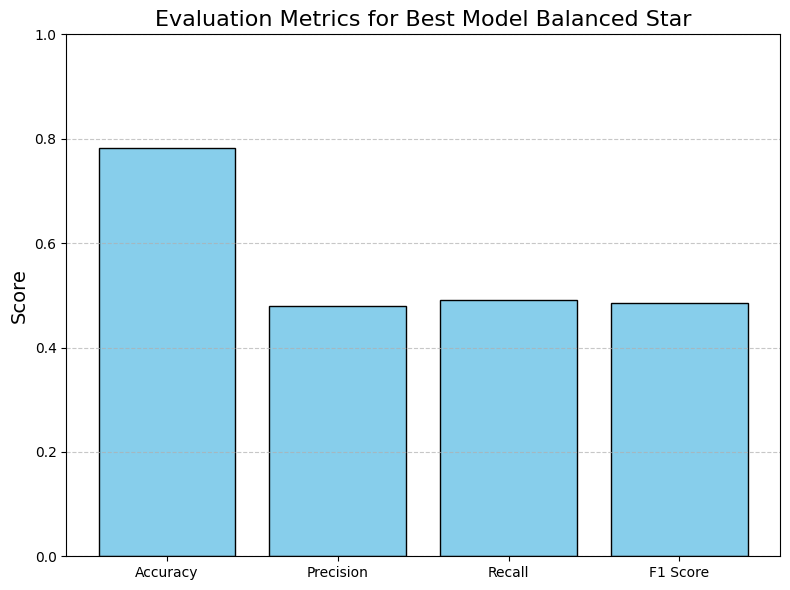

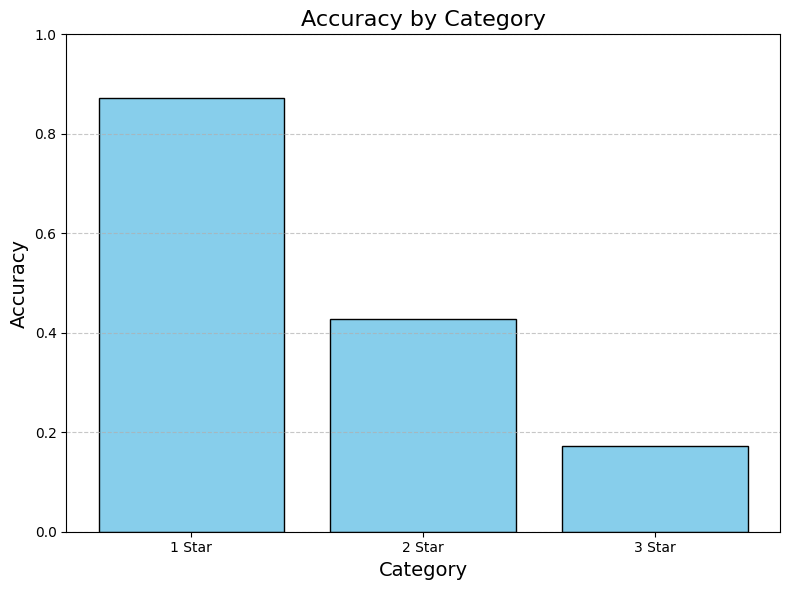

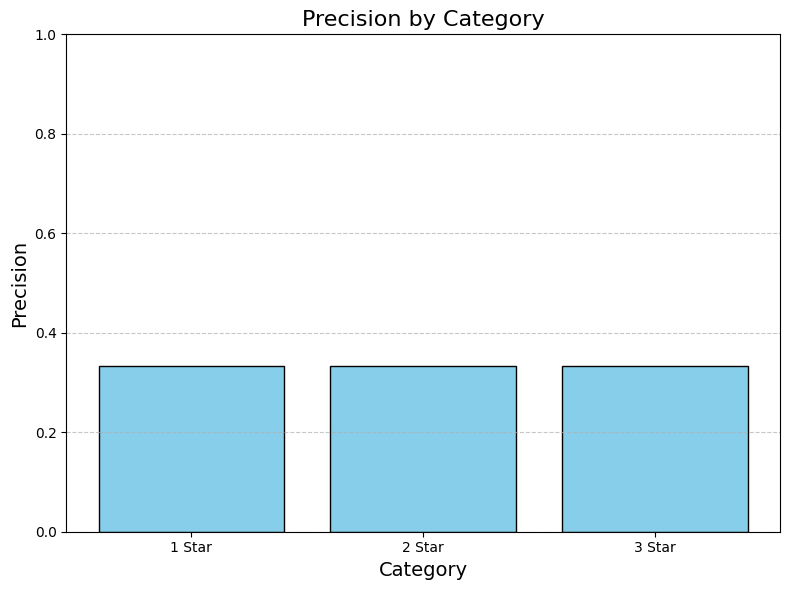

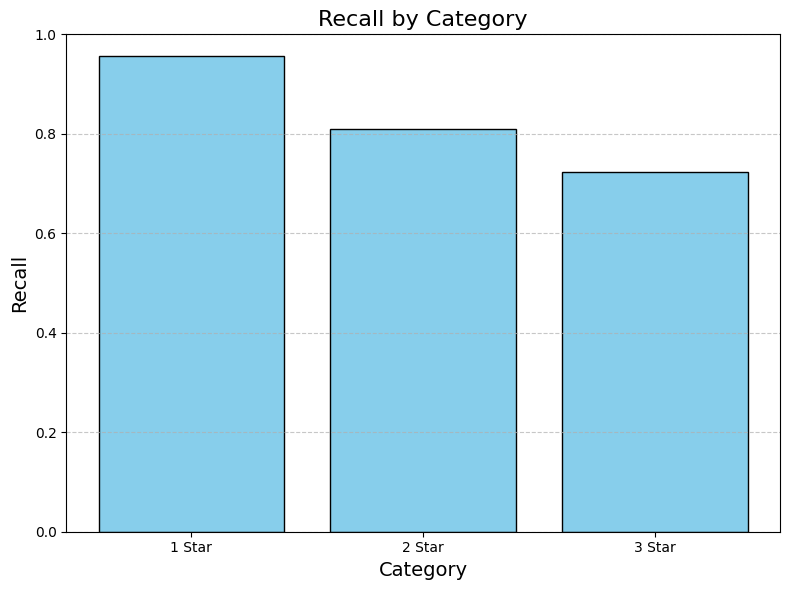

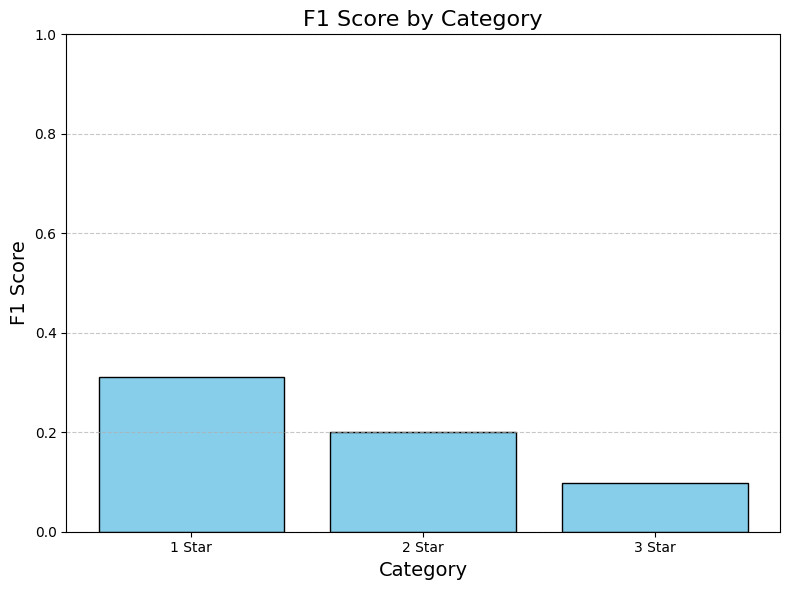


==================== Evaluation Metrics ====================

Category: 1 Star
Accuracy: 0.8714
Precision: 0.3333
Recall: 0.9571
F1 Score: 0.3104
Data Count: 591

Category: 2 Star
Accuracy: 0.4286
Precision: 0.3333
Recall: 0.8095
F1 Score: 0.2000
Data Count: 98

Category: 3 Star
Accuracy: 0.1724
Precision: 0.3333
Recall: 0.7241
F1 Score: 0.0980
Data Count: 29


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, Concatenate, Lambda
from tensorflow.keras import backend as K
from sklearn.preprocessing import StandardScaler

# ---------------------------
# 사전에 학습된 임베딩 모델 및 매핑 정보가 있다고 가정:
# model_city_region_star, model_cuisine_star
# city_map, region_map, cuisine_map
# split_cuisines, cuisines_to_idx_list, pad_cuisine_idx_list, max_cuisine_count 등
# ---------------------------

def get_penultimate_output(model, inputs):
    # 모델의 penultimate layer(마지막 이전 Dense 레이어) 출력
    hidden_layer = model.layers[-2].output
    temp_model = Model(model.inputs, hidden_layer)
    return temp_model.predict(inputs)

def preprocess_for_prediction(data, target='Stars'):
    # target='Stars'일 경우 (c) (d) 모델 사용
    c_idx = data['City'].apply(lambda x: city_map.get(x,0)).values
    r_idx = data['Region'].apply(lambda x: region_map.get(x,0)).values
    lat = data['Latitude'].values
    lon = data['Longitude'].values
    
    c_list = data['Cuisine'].apply(split_cuisines).apply(lambda x: cuisines_to_idx_list(x))
    c_array = np.array(c_list.apply(lambda x: pad_cuisine_idx_list(x, max_cuisine_count)).tolist())
    
    city_region_input = [c_idx, r_idx, lat, lon]
    cuisine_input = c_array
    
    city_region_emb = get_penultimate_output(model_city_region_star, city_region_input)
    cuisine_emb = get_penultimate_output(model_cuisine_star, cuisine_input)
    
    X_final = np.concatenate([city_region_emb, cuisine_emb], axis=1)
    
    y = data[target].values
    return X_final, y

# ---------------------------
# 여기서부터는 SMOTE 및 모델 학습/평가 코드
# ---------------------------

# 데이터 로드
file_path1 = './kaggle/input/michelin-restaurants/one-star-michelin-restaurants-2024.csv'
file_path2 = './kaggle/input/michelin-restaurants/two-stars-michelin-restaurants-2024.csv'
file_path3 = './kaggle/input/michelin-restaurants/three-stars-michelin-restaurants-2024.csv'

data1 = pd.read_csv(file_path1)  # 1스타
data2 = pd.read_csv(file_path2)  # 2스타
data3 = pd.read_csv(file_path3)  # 3스타

for d in [data1, data2, data3]:
    d['Region'] = d['Region'].fillna(d['City'])
    d['Stars'] = d['Stars'].astype(int) - 1
    d['Price'] = d['Price'] - 1

data_combined = pd.concat([data1, data2, data3], axis=0)

X, y = preprocess_for_prediction(data_combined, target='Stars')

# train/test split
X_train, X_test_star, y_train, y_test_star = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Original training set distribution:", dict(pd.Series(y_train).value_counts()))
print("Resampled training set distribution:", dict(pd.Series(y_train_resampled).value_counts()))

# 스케일러를 여기서 한 번만 fit
scaler = StandardScaler()
X_train_resampled = scaler.fit_transform(X_train_resampled)
X_test = scaler.transform(X_test_star)

best_model_balanced_star = RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100)
best_model_balanced_star.fit(X_train_resampled, y_train_resampled)

y_pred = best_model_balanced_star.predict(X_test)

evaluation_results = {
    'Accuracy': accuracy_score(y_test_star, y_pred),
    'Precision': precision_score(y_test_star, y_pred, average='macro', zero_division=1),
    'Recall': recall_score(y_test_star, y_pred, average='macro', zero_division=1),
    'F1 Score': f1_score(y_test_star, y_pred, average='macro', zero_division=1)
}

print("\nBest Model Balanced Star Evaluation Results:")
for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")

def plot_evaluation_metrics(results, title):
    metrics = list(results.keys())
    values = list(results.values())

    plt.figure(figsize=(8, 6))
    plt.bar(metrics, values, color='skyblue', edgecolor='black')
    plt.title(title, fontsize=16)
    plt.ylabel("Score", fontsize=14)
    plt.ylim(0, 1)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_evaluation_metrics(evaluation_results, "Evaluation Metrics for Best Model Balanced Star")

# 각 스타 카테고리별 평가
results_by_category = {}

for star_value, name in zip([0, 1, 2], ['1 Star', '2 Star', '3 Star']):
    # 테스트 데이터에서 해당 스타 값에 해당하는 데이터만 필터링
    category_mask = y_test_star == star_value
    X_cat = X_test[category_mask]
    y_cat = y_test_star[category_mask]

    y_pred_cat = best_model_balanced_star.predict(X_cat)

    results = {
        'Accuracy': accuracy_score(y_cat, y_pred_cat),
        'Precision': precision_score(y_cat, y_pred_cat, average='macro', zero_division=1),
        'Recall': recall_score(y_cat, y_pred_cat, average='macro', zero_division=1),
        'F1 Score': f1_score(y_cat, y_pred_cat, average='macro', zero_division=1),
        'Data Count': len(y_cat)  # 테스트 데이터 개수
    }
    results_by_category[name] = results

def plot_evaluation_metrics_by_category(results):
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
    categories = list(results.keys())
    metric_values = {metric: [results[cat][metric] for cat in categories] for metric in metrics}

    for metric in metrics:
        plt.figure(figsize=(8, 6))
        plt.bar(categories, metric_values[metric], color='skyblue', edgecolor='black')
        plt.title(f"{metric} by Category", fontsize=16)
        plt.xlabel('Category', fontsize=14)
        plt.ylabel(metric, fontsize=14)
        plt.ylim(0, 1)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    # 텍스트 출력
    print(f"\n{'='*20} Evaluation Metrics {'='*20}")
    for cat, mtrcs in results.items():
        print(f"\nCategory: {cat}")
        for metric, value in mtrcs.items():
            if metric == 'Data Count':
                print(f"{metric}: {value}")  # 데이터 개수는 소수점 없이 출력
            else:
                print(f"{metric}: {value:.4f}")

plot_evaluation_metrics_by_category(results_by_category)


113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 764us/step


/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(32, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/layers/layer.py:932: UserWarning: Layer 'lambda' (of type Lambda) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(None, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/sklearn/base.py:474:

Original training set distribution: {3: 1809, 2: 983, 1: 77, 0: 2}
Resampled training set distribution: {3: 1809, 2: 1809, 1: 1809, 0: 1809}

Best Model Balanced Price Evaluation Results:
Accuracy: 0.3510
Precision: 0.3276
Recall: 0.3243
F1 Score: 0.2753


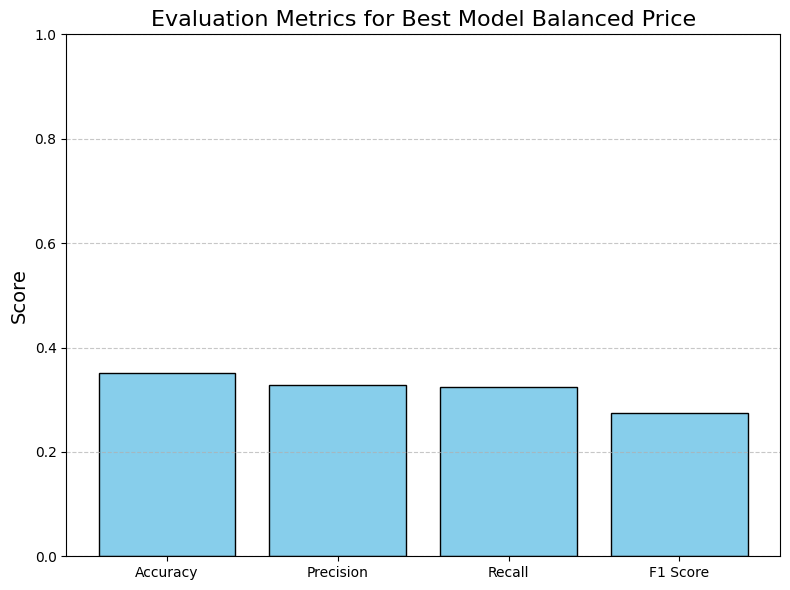

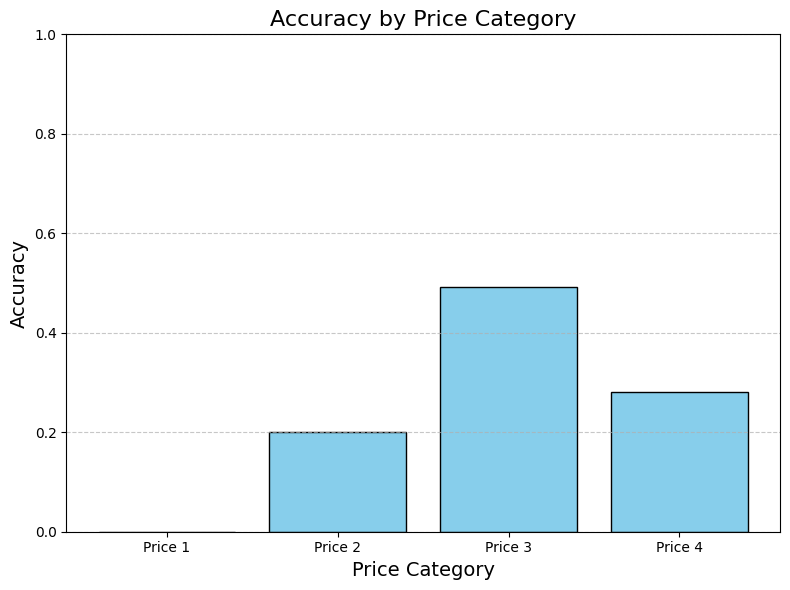

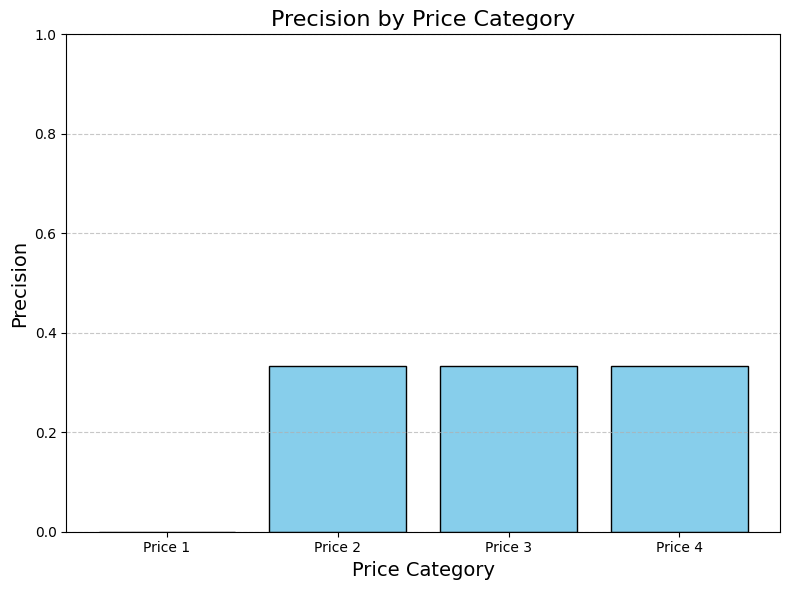

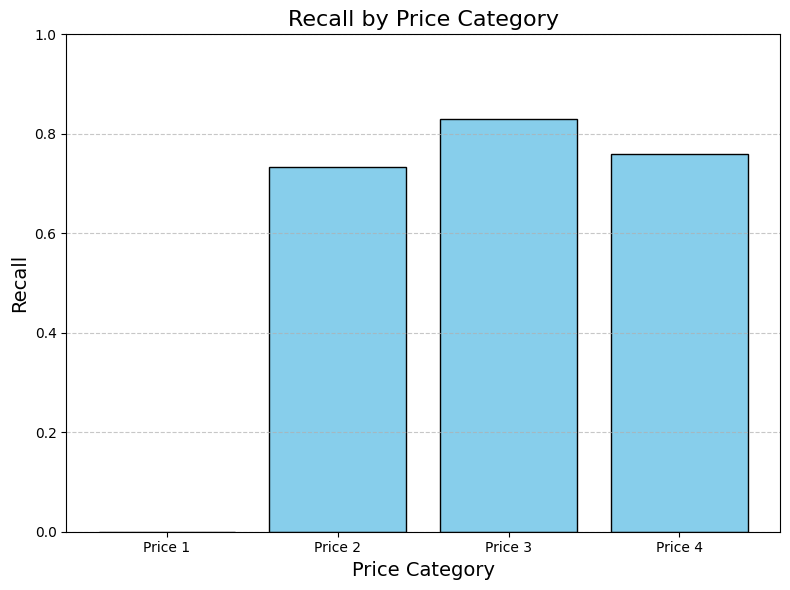

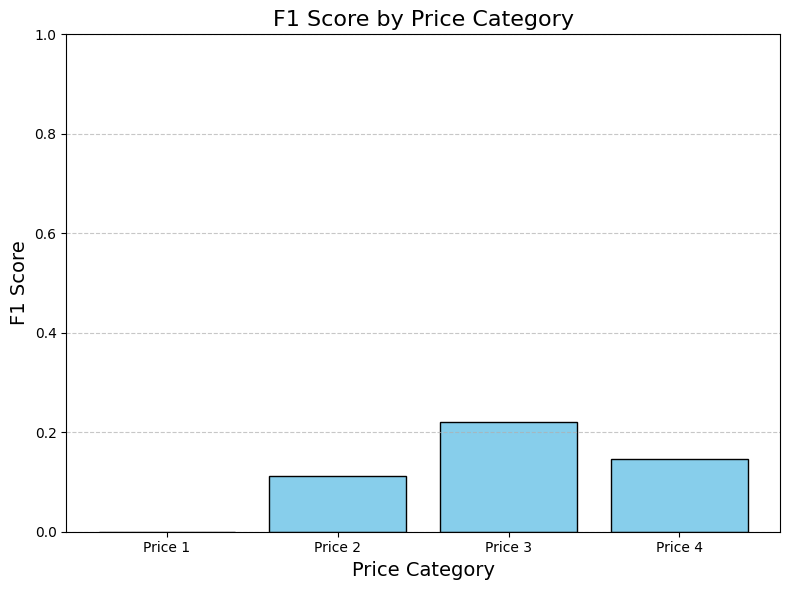


==================== Evaluation Metrics by Price Category ====================

Category: Price 1
Accuracy: No Data
Precision: No Data
Recall: No Data
F1 Score: No Data
Data Count: 0

Category: Price 2
Accuracy: 0.2000
Precision: 0.3333
Recall: 0.7333
F1 Score: 0.1111
Data Count: 20

Category: Price 3
Accuracy: 0.4919
Precision: 0.3333
Recall: 0.8306
F1 Score: 0.2198
Data Count: 246

Category: Price 4
Accuracy: 0.2810
Precision: 0.3333
Recall: 0.7603
F1 Score: 0.1462
Data Count: 452


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, Concatenate, Lambda
from tensorflow.keras import backend as K
from sklearn.preprocessing import StandardScaler

# ---------------------------
# 사전에 학습된 임베딩 모델 및 매핑 정보가 있다고 가정:
# model_city_region_price, model_cuisine_price
# city_map, region_map, cuisine_map
# split_cuisines, cuisines_to_idx_list, pad_cuisine_idx_list, max_cuisine_count 등
# ---------------------------

def get_penultimate_output(model, inputs):
    # 모델의 penultimate layer(마지막 이전 Dense 레이어) 출력
    hidden_layer = model.layers[-2].output
    temp_model = Model(model.inputs, hidden_layer)
    return temp_model.predict(inputs)

def preprocess_for_prediction(data, target='Price'):
    """
    Price 예측을 위한 임베딩 추출 과정
    target='Price'일 경우:
    - model_city_region_price, model_cuisine_price를 사용하여 임베딩 벡터 추출
    """
    c_idx = data['City'].apply(lambda x: city_map.get(x,0)).values
    r_idx = data['Region'].apply(lambda x: region_map.get(x,0)).values
    lat = data['Latitude'].values
    lon = data['Longitude'].values

    c_list = data['Cuisine'].apply(split_cuisines).apply(lambda x: cuisines_to_idx_list(x))
    c_array = np.array(c_list.apply(lambda x: pad_cuisine_idx_list(x, max_cuisine_count)).tolist())

    # Price 예측용 임베딩 모델 사용
    city_region_input = [c_idx, r_idx, lat, lon]
    cuisine_input = c_array

    # City/Region 임베딩 추출 (Price 모델)
    city_region_emb = get_penultimate_output(model_city_region_price, city_region_input)
    # Cuisine 임베딩 추출 (Price 모델)
    cuisine_emb = get_penultimate_output(model_cuisine_price, cuisine_input)

    X_final = np.concatenate([city_region_emb, cuisine_emb], axis=1)
    y = data[target].values
    return X_final, y


# ---------------------------
# 여기서부터는 Price 예측용 SMOTE 및 모델 학습/평가 코드
# ---------------------------

# 데이터 로드
file_path1 = './kaggle/input/michelin-restaurants/one-star-michelin-restaurants-2024.csv'
file_path2 = './kaggle/input/michelin-restaurants/two-stars-michelin-restaurants-2024.csv'
file_path3 = './kaggle/input/michelin-restaurants/three-stars-michelin-restaurants-2024.csv'

data1 = pd.read_csv(file_path1)  # 1스타
data2 = pd.read_csv(file_path2)  # 2스타
data3 = pd.read_csv(file_path3)  # 3스타

for d in [data1, data2, data3]:
    d['Region'] = d['Region'].fillna(d['City'])
    d['Stars'] = d['Stars'].astype(int) - 1
    d['Price'] = d['Price'] - 1

data_combined = pd.concat([data1, data2, data3], axis=0)

# Price 예측용 데이터 준비
X, y = preprocess_for_prediction(data_combined, target='Price')

# train/test split
X_train, X_test_price, y_train, y_test_price = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SMOTE 적용
smote = SMOTE(random_state=42, k_neighbors=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Original training set distribution:", dict(pd.Series(y_train).value_counts()))
print("Resampled training set distribution:", dict(pd.Series(y_train_resampled).value_counts()))

# 스케일링
scaler = StandardScaler()
X_train_resampled = scaler.fit_transform(X_train_resampled)
X_test = scaler.transform(X_test)

best_model_balanced_price = RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100)
best_model_balanced_price.fit(X_train_resampled, y_train_resampled)

y_pred = best_model_balanced_price.predict(X_test)

evaluation_results = {
    'Accuracy': accuracy_score(y_test_price, y_pred),
    'Precision': precision_score(y_test_price, y_pred, average='macro', zero_division=1),
    'Recall': recall_score(y_test_price, y_pred, average='macro', zero_division=1),
    'F1 Score': f1_score(y_test_price, y_pred, average='macro', zero_division=1)
}

print("\nBest Model Balanced Price Evaluation Results:")
for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")

def plot_evaluation_metrics(results, title):
    metrics = list(results.keys())
    values = list(results.values())

    plt.figure(figsize=(8, 6))
    plt.bar(metrics, values, color='skyblue', edgecolor='black')
    plt.title(title, fontsize=16)
    plt.ylabel("Score", fontsize=14)
    plt.ylim(0, 1)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_evaluation_metrics(evaluation_results, "Evaluation Metrics for Best Model Balanced Price")

# 테스트 데이터에서 각 Price 카테고리별 평가
results_by_price_category = {}

for p in range(4):  # Price는 0, 1, 2, 3
    # 테스트 데이터에서 특정 Price 카테고리 데이터만 필터링
    price_mask = y_test_price == p
    X_price_cat = X_test[price_mask]
    y_price_cat = y_test_price[price_mask]

    # 데이터가 없는 경우를 처리
    if X_price_cat.shape[0] == 0:
        results = {
            'Accuracy': None,
            'Precision': None,
            'Recall': None,
            'F1 Score': None,
            'Data Count': 0  # 데이터 개수만 기록
        }
    else:
        y_pred_price_cat = best_model_balanced_price.predict(X_price_cat)
        results = {
            'Accuracy': accuracy_score(y_price_cat, y_pred_price_cat),
            'Precision': precision_score(y_price_cat, y_pred_price_cat, average='macro', zero_division=1),
            'Recall': recall_score(y_price_cat, y_pred_price_cat, average='macro', zero_division=1),
            'F1 Score': f1_score(y_price_cat, y_pred_price_cat, average='macro', zero_division=1),
            'Data Count': len(y_price_cat)  # 데이터 개수
        }
    results_by_price_category[f'Price {p+1}'] = results

def plot_evaluation_metrics_by_price_category(results):
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
    categories = list(results.keys())
    # None 값을 0으로 대체
    metric_values = {
        metric: [
            results[cat][metric] if results[cat][metric] is not None else 0
            for cat in categories
        ]
        for metric in metrics
    }

    for metric in metrics:
        plt.figure(figsize=(8, 6))
        plt.bar(categories, metric_values[metric], color='skyblue', edgecolor='black')
        plt.title(f"{metric} by Price Category", fontsize=16)
        plt.xlabel('Price Category', fontsize=14)
        plt.ylabel(metric, fontsize=14)
        plt.ylim(0, 1)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    # 텍스트 출력
    print(f"\n{'='*20} Evaluation Metrics by Price Category {'='*20}")
    for cat, mtrcs in results_by_price_category.items():
        print(f"\nCategory: {cat}")
        for metric, value in mtrcs.items():
            if value is None:
                print(f"{metric}: No Data")  # None 값을 "No Data"로 출력
            else:
                if metric == 'Data Count':
                    print(f"{metric}: {value}")  # 정수 값은 소수점 없이 출력
                else:
                    print(f"{metric}: {value:.4f}")  # 소수점 형식 출력


plot_evaluation_metrics_by_price_category(results_by_price_category)


In [19]:
def predict_category(new_data, target):
    """
    단일 데이터 포인트에 대해 Star 또는 Price를 예측하는 함수.

    Parameters:
    - new_data (dict): 예측에 필요한 입력 데이터를 포함한 딕셔너리.
    - target (str): 예측할 타겟 ('Stars' 또는 'Price').

    Returns:
    - 예측된 카테고리 (int): 예측된 Star 또는 Price 값 (1부터 시작).
    """
    # 입력 데이터를 DataFrame으로 변환
    new_data_df = pd.DataFrame(new_data)

    # 전처리 수행
    X_new, _ = preprocess_for_prediction(new_data_df, target=target)

    # 동일한 스케일러 적용
    X_new_scaled = scaler.transform(X_new)

    # 모델 선택 및 예측
    if target == 'Stars':
        predicted_category = best_model_balanced_star.predict(X_new_scaled)
        # 예측된 Star 범주를 1부터 시작하는 값으로 복원
        return predicted_category[0] + 1
    elif target == 'Price':
        predicted_category = best_model_balanced_price.predict(X_new_scaled)
        # 예측된 Price 범주를 1부터 시작하는 값으로 복원
        return predicted_category[0] + 1
    else:
        raise ValueError("Invalid target. Choose 'Stars' or 'Price'.")


# 사용 예시
new_data_mosu = {
    'Latitude': [37.63695556],
    'Longitude' : [127.0277194],
    'City': ['Seoul'],
    'Region': ['South Korea'],
    'Cuisine': ['Innovative'],
    'Stars': [2],  # 3스타였다고 치면 2로 (0부터 시작)
    'Price': [3]   # 실제 예측 대상일 경우에는(Price 예측인 경우) dummy 데이터 넣어도 됨
}

# Star 예측
predicted_star_category_mosu = predict_category(new_data_mosu, target='Stars')
print(f"Predicted Star Category for Mosu: {predicted_star_category_mosu}")

# Price 예측
predicted_price_category_mosu = predict_category(new_data_mosu, target='Price')
print(f"Predicted Price Category for Mosu: {predicted_price_category_mosu}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Predicted Star Category for Mosu: 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Predicted Price Category for Mosu: 4


/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(1, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/layers/layer.py:932: UserWarning: Layer 'lambda' (of type Lambda) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(1, 2))
  warnings.warn(msg)
/home/ktw/.pyenv/versions/3.11.4/envs/xtwice/lib/python3.11/site-packages/keras/src/layers/layer.p